In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Una obra de urbanización consume agua en el curado del hormigón, el riego de compactación de los rellenos, el control del polvo y el lavado de maquinaria. El cuadro de prelaciones, las duraciones (semanas) y el consumo semanal de agua de cada actividad (`agua_m3`, m³ por semana mientras está en curso) se adjuntan. El agua se toma de la red municipal con un contador de obra (2.5 €/m³).

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, agua_m3
    ('A'     , '---'      , 8       , 0      ),
    ('B'     , '---'      , 5       , 0      ),
    ('C'     , 'A,B'      , 1       , 0      ),
    ('D'     , 'B'        , 2       , 10     ),
    ('E'     , 'A,B'      , 3       , 40     ),
    ('F'     , 'B'        , 7       , 10     ),
    ('G'     , 'C,D'      , 5       , 40     ),
    ('H'     , 'E,F'      , 3       , 0      ),
    ('I'     , 'H'        , 4       , 0      ),
], columns=['activity', 'predecessor', 'duration', 'agua_m3']).set_index('activity')
datos_enunciado

,predecessor,duration,agua_m3
activity,,,
A,---,8,0
B,---,5,0
C,"A,B",1,0
D,B,2,10
E,"A,B",3,40
F,B,7,10
G,"C,D",5,40
H,"E,F",3,0
I,H,4,0


El organismo de cuenca ha declarado la situación excepcional por sequía y el ayuntamiento, por bando, limita el consumo de las obras a **50 m³ por semana** por contador. El agua que falte puede traerse en camión cuba desde un punto de carga autorizado a 20 km, a 14.0 €/m³ (agua y porte). El retraso de la entrega tiene una penalidad de 6 k€ por semana. El reglamento del servicio sanciona la conexión no autorizada a un hidrante con 30 k€ y el corte del suministro de obra (2 semana(s) hasta restablecerlo); por la experiencia de la empresa, la probabilidad de que se detecte es del 50%.

> **De: Jefe de obra**
> Con el plan de inicios más tempranos hay semanas en que necesitamos 90 m³ y nos dan 50. No vamos a retrasar la obra por una sequía: el exceso lo sacamos del hidrante de la esquina por la noche, que el contador de obra no lo ve, y si alguien pregunta es agua de la cuba. La cuba de verdad, sólo si no queda otra.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 20 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **S16 — Cuotas de recursos impuestas por la autoridad.** Cuando la autoridad limita un recurso (agua en sequía, potencia, ocupación de vía pública, horas de maquinaria), la cuota es un límite del plan como lo es el número de operarios: se nivela dentro de las holguras y, si no cabe, se asigna con límite (lección 11) o se compra el recurso fuera, con su coste. Obtener el recurso saltándose la limitación es infracción, no una opción de la tabla; y si el plan cabe o no en la cuota tras nivelar lo dice el diagrama de cargas, no la opinión. *(cf. Texto refundido de la Ley de Aguas (RDL 1/2001), arts. 55.2, 58 y 116.3.b) y c); bando municipal de sequía (Ley 7/1985, arts. 25.2.c) y 26.1.a), abastecimiento); PMBOK 8 §3.7.3 (dominio de recursos).)*
- **S11 — Riesgo de sostenibilidad.** Una amenaza ambiental, climática, regulatoria o social que puede cambiar el plazo, el coste o el resultado del proyecto es un riesgo del proyecto: entra en el registro con su probabilidad y su impacto y se cuantifica en el cronograma como cualquier otro. Dejarlo fuera «porque es el clima» o «porque es de la administración» es retener información (C4 de la lección 19). *(cf. PMBOK 8 §3.7.1 (riesgos de sostenibilidad) y §3.7.3 (dominio de desempeño del riesgo).)*
- **S1 — Jerarquía de respuesta a los impactos (pirámide de sostenibilidad).** Ante un impacto negativo del proyecto las estrategias se ordenan de menos a más deseable: compensar o contrarrestar el daño, restaurarlo, minimizarlo y evitarlo. Compensar cuando se podía minimizar o evitar es quedarse en el escalón más bajo; clasificar una propuesta en su escalón es una pregunta con respuesta única. *(cf. PMBOK 8, principio «integrar la sostenibilidad en todas las áreas del proyecto» (§3.7, figura 3-7).)*
- **Norma o dato de referencia — en situaciones de sequía el organismo de cuenca puede condicionar o limitar el uso del dominio público hidráulico y el Gobierno adoptar por real decreto medidas excepcionales aunque afecten a concesiones; derivar agua sin concesión o autorización e incumplir las condiciones de las concesiones y autorizaciones son infracciones administrativas; el abastecimiento de agua es competencia municipal y el ayuntamiento fija por bando las restricciones de consumo y, en el reglamento del servicio, las sanciones por conexiones no autorizadas (hidrantes, tomas fraudulentas)** *(TRLA (RDL 1/2001), arts. 55.2, 58 y 116.3.b) y c); Ley 7/1985, arts. 25.2.c) y 26.1.a).)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Dibuje el diagrama de cargas de agua con inicios más tempranos y obtenga el pico y el exceso sobre los 50 m³ semanales, semana a semana. Nivele las cargas dentro de las holguras y repita el cálculo: ¿cabe el plan nivelado en la cuota sin alargar el proyecto?  "
pregunta_2 = "2. (A) Calcule el coste de las opciones legales: traer en cuba el exceso del plan inicial, traer en cuba el exceso del plan nivelado, y programar con asignación limitada a 50 m³ por semana (duración, retraso y penalidad). Calcule también el coste esperado de la propuesta del hidrante. ¿Cuál es la opción legal más barata?  "
pregunta_3 = "3. (B) Según el criterio y la norma de referencia, ¿es la cuota un límite del plan o un riesgo que se acepta? ¿Cabe el plan en la cuota tras nivelar, sin retraso? ¿Es el hidrante una opción de la tabla? ¿En qué escalón de la pirámide queda cada opción?  "
pregunta_4 = "4. (C) ¿Qué propone al jefe de obra y qué comunica al cliente y al ayuntamiento? Aplique la rúbrica.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Dibuje el diagrama de cargas de agua con inicios más tempranos y obtenga el pico y el exceso sobre los 50 m³ semanales, semana a semana. Nivele las cargas dentro de las holguras y repita el cálculo: ¿cabe el plan nivelado en la cuota sin alargar el proyecto?  

2. (A) Calcule el coste de las opciones legales: traer en cuba el exceso del plan inicial, traer en cuba el exceso del plan nivelado, y programar con asignación limitada a 50 m³ por semana (duración, retraso y penalidad). Calcule también el coste esperado de la propuesta del hidrante. ¿Cuál es la opción legal más barata?  

3. (B) Según el criterio y la norma de referencia, ¿es la cuota un límite del plan o un riesgo que se acepta? ¿Cabe el plan en la cuota tras nivelar, sin retraso? ¿Es el hidrante una opción de la tabla? ¿En qué escalón de la pirámide queda cada opción?  

4. (C) ¿Qué propone al jefe de obra y qué comunica al cliente y al ayuntamiento? Aplique la rúbrica.  

# Resolución

In [6]:
cuota, coste_cuba, km_cuba, precio_red, penalidad, multa, corte, p_deteccion = 50, 14.0, 20, 2.5, 6, 30, 2, 0.5
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

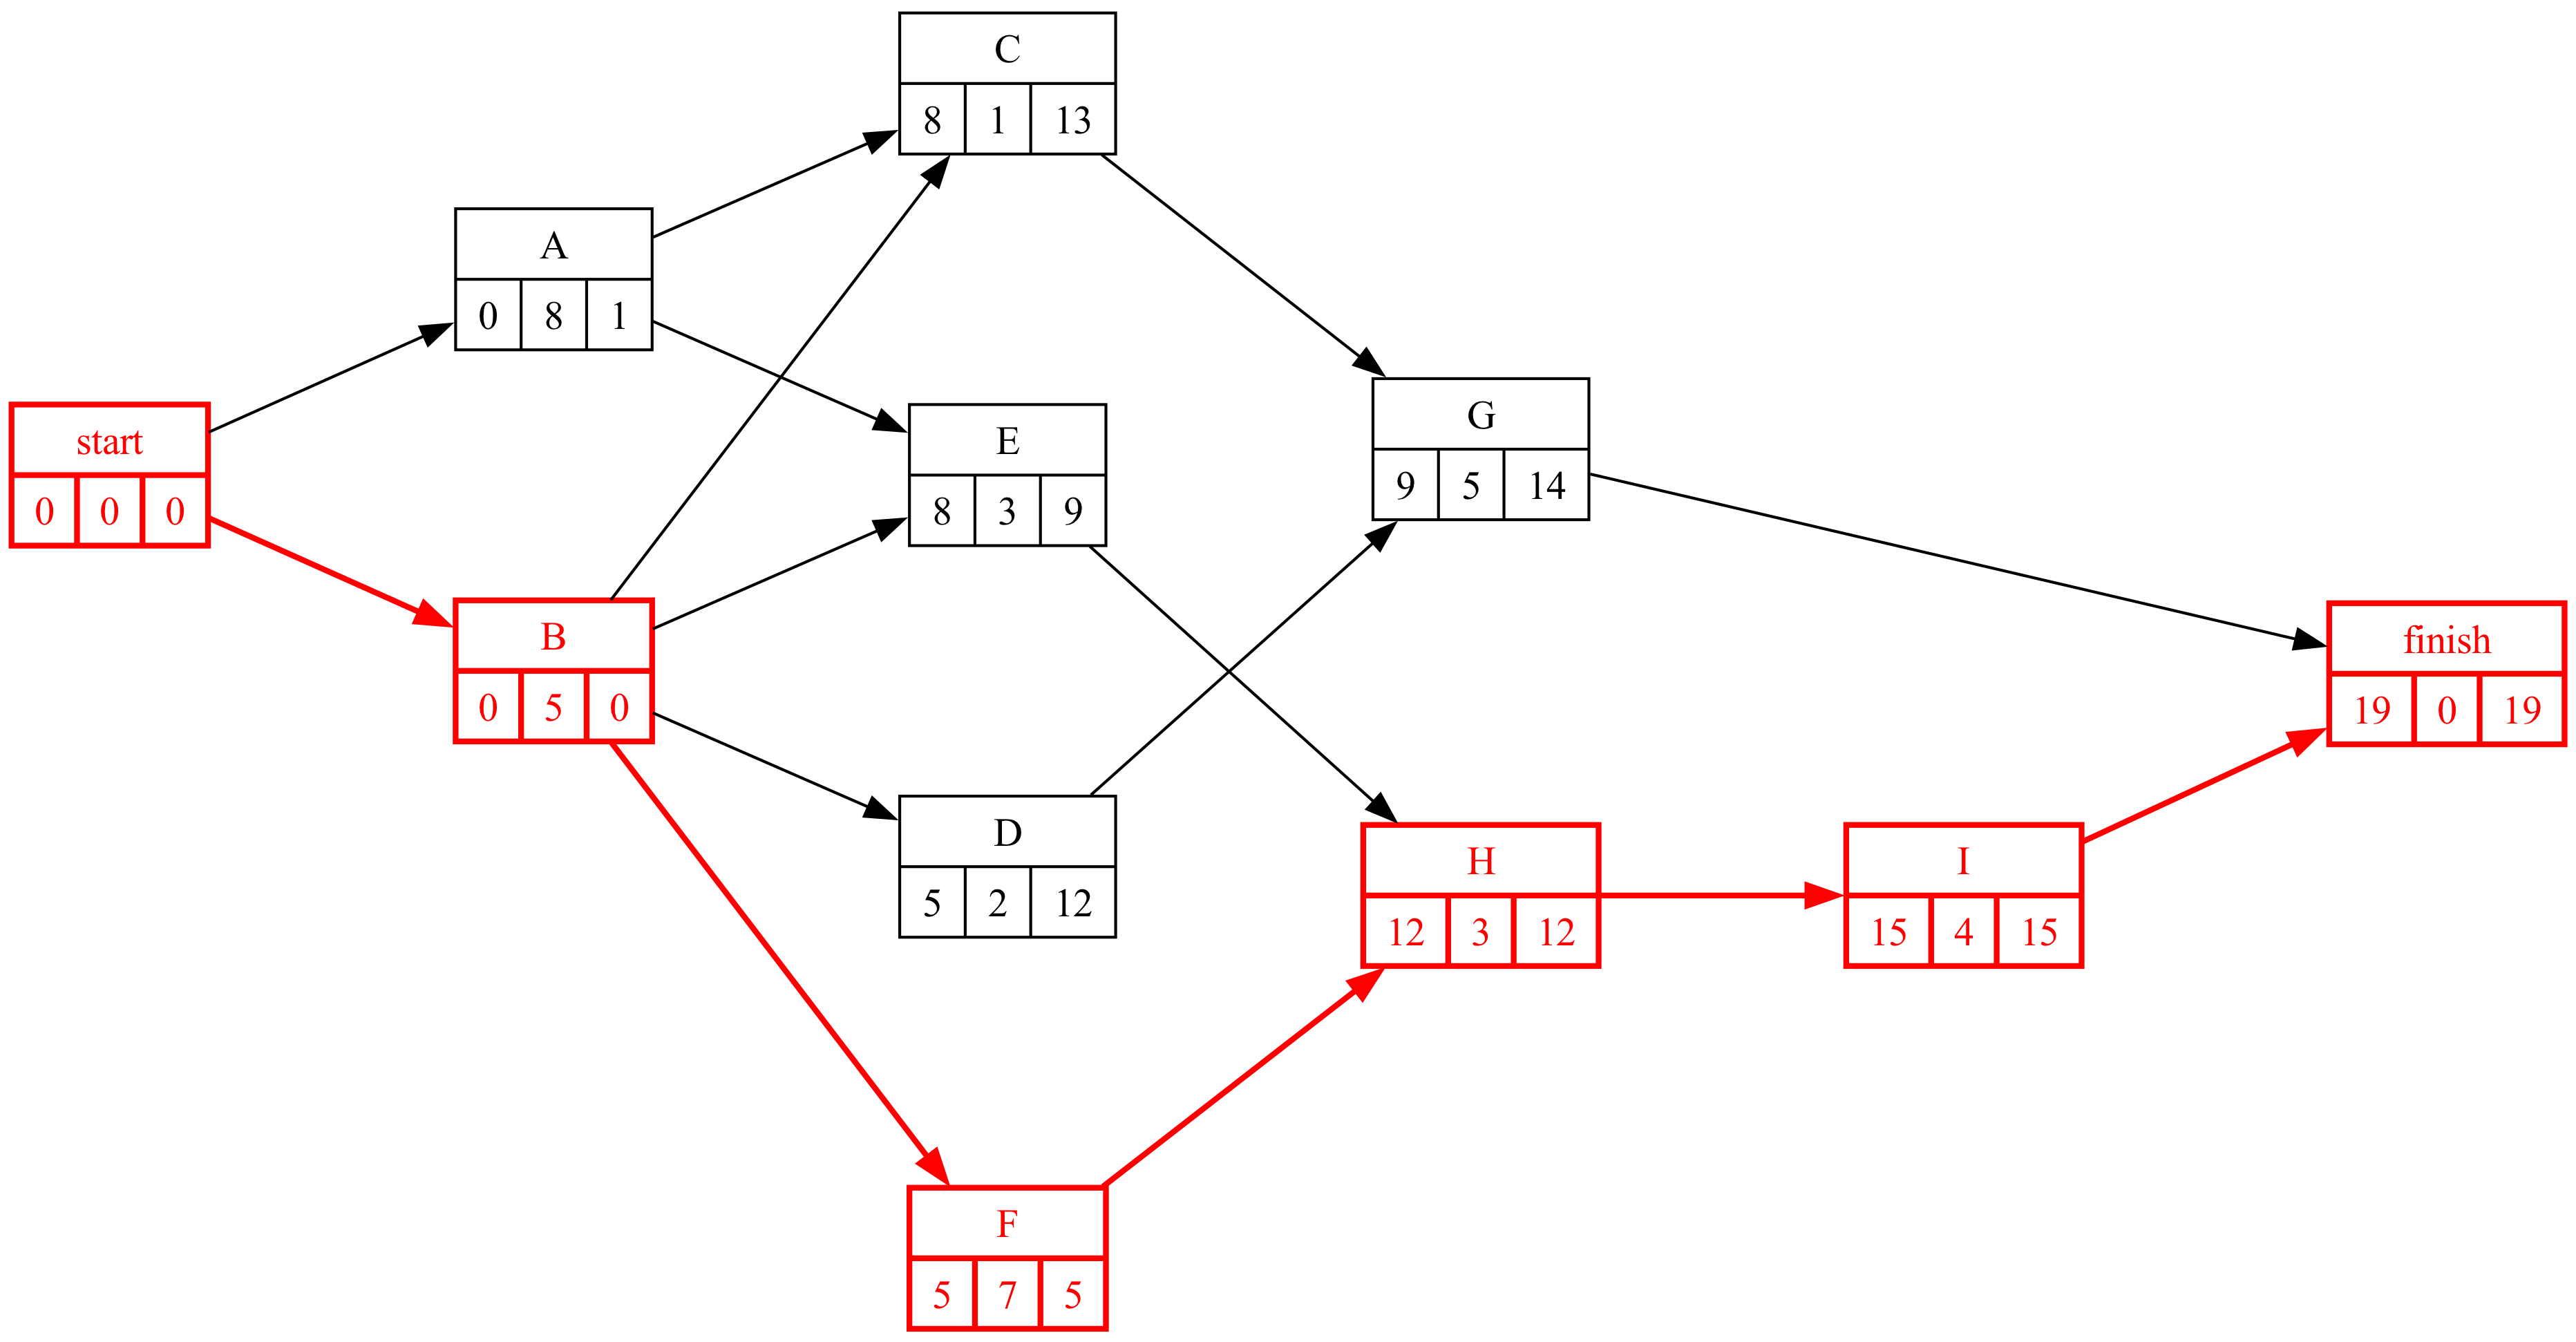

In [8]:
#| fig-cap: "Grafo Roy del proyecto"
#| label: fig-pert
proyecto.display_roy_pasos(datos_proyecto['duration'])

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Dibuje el diagrama de cargas de agua con inicios más tempranos y obtenga el pico y el exceso sobre los 50 m³ semanales, semana a semana. Nivele las cargas dentro de las holguras y repita el cálculo: ¿cabe el plan nivelado en la cuota sin alargar el proyecto?  

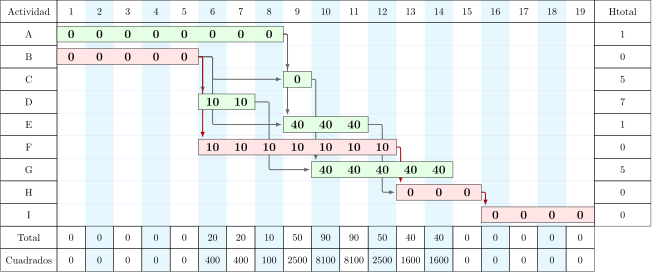

In [10]:
#| fig-cap: "Gantt con inicios más tempranos y consumo de agua (m³ por semana)"
#| label: fig-ganttCargas
gantt_inicial, dibujo = proyecto.copy().gantt_cargas(datos_proyecto.copy(), 'duration', 'agua_m3', report=False, tikz=True, params=GANTT_PARAMS)
pinta_tikz(dibujo)

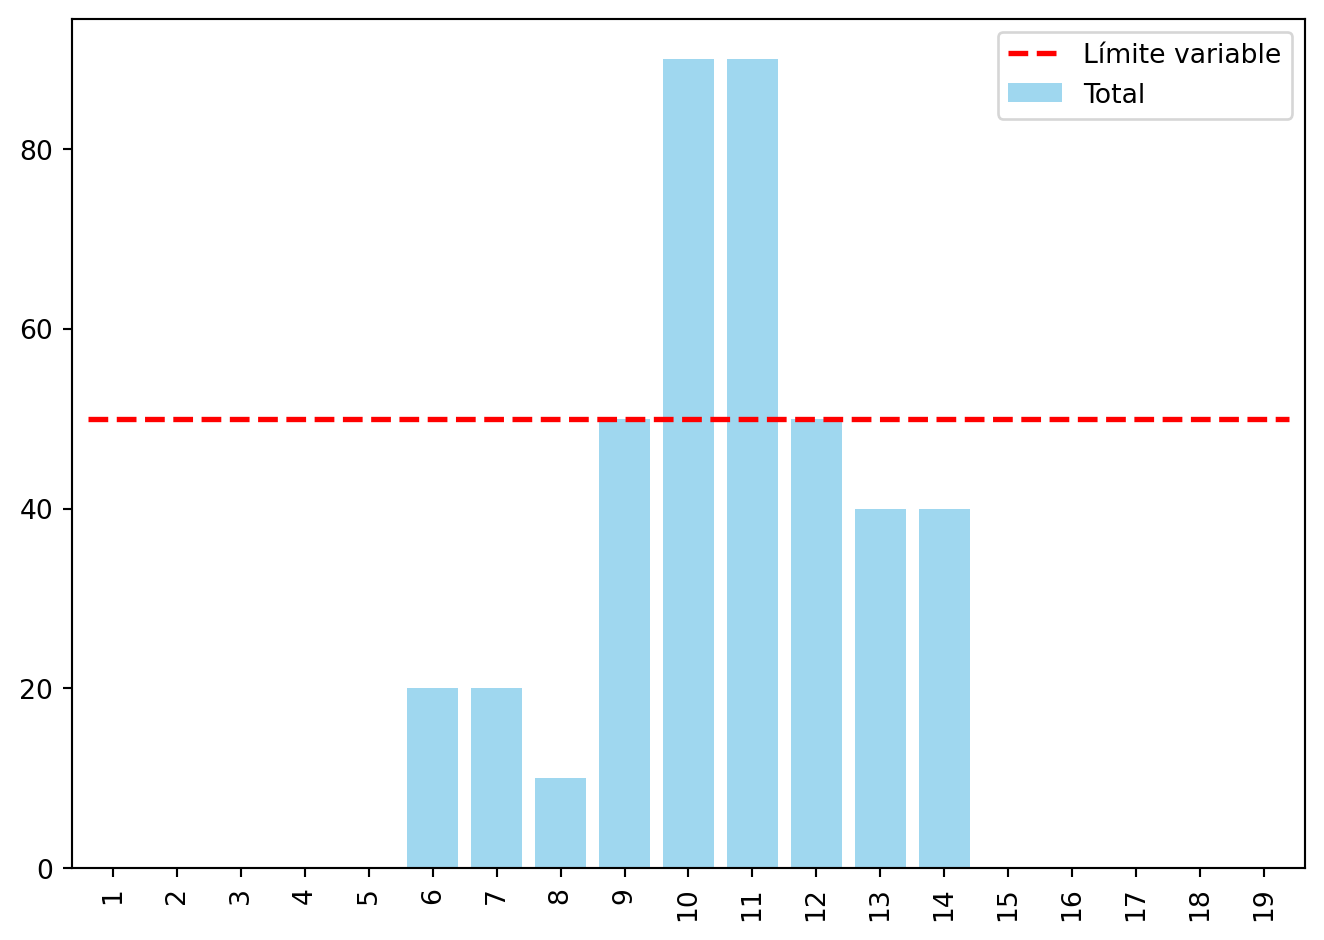

In [11]:
#| fig-cap: "Diagrama de cargas de agua frente a la cuota del bando"
#| label: fig-cargas
cargas = gantt_inicial.data.loc['Total'].drop('H_total').astype(float)
plot_cargas(gantt_df=gantt_inicial, limite_maximo_recursos=[cuota])

In [12]:
#| tbl-cap: "Desplazamientos de la nivelación (suma de cuadrados mínima dentro de las holguras)"
#| label: tbl-nivelacion
proyecto_nivelado = proyecto.copy()
desplazamientos, cuadrados, datos_nivelados, gantt_nivelado, dibujo_niv = proyecto_nivelado.nivelar(
    data=datos_proyecto.copy(), duration_label='duration', resource_label='agua_m3')
cargas_niveladas = gantt_nivelado.data.loc['Total'].drop('H_total').astype(float)
desplazamientos[desplazamientos['desplazamientos'] > 0]

,desplazamientos
D,7


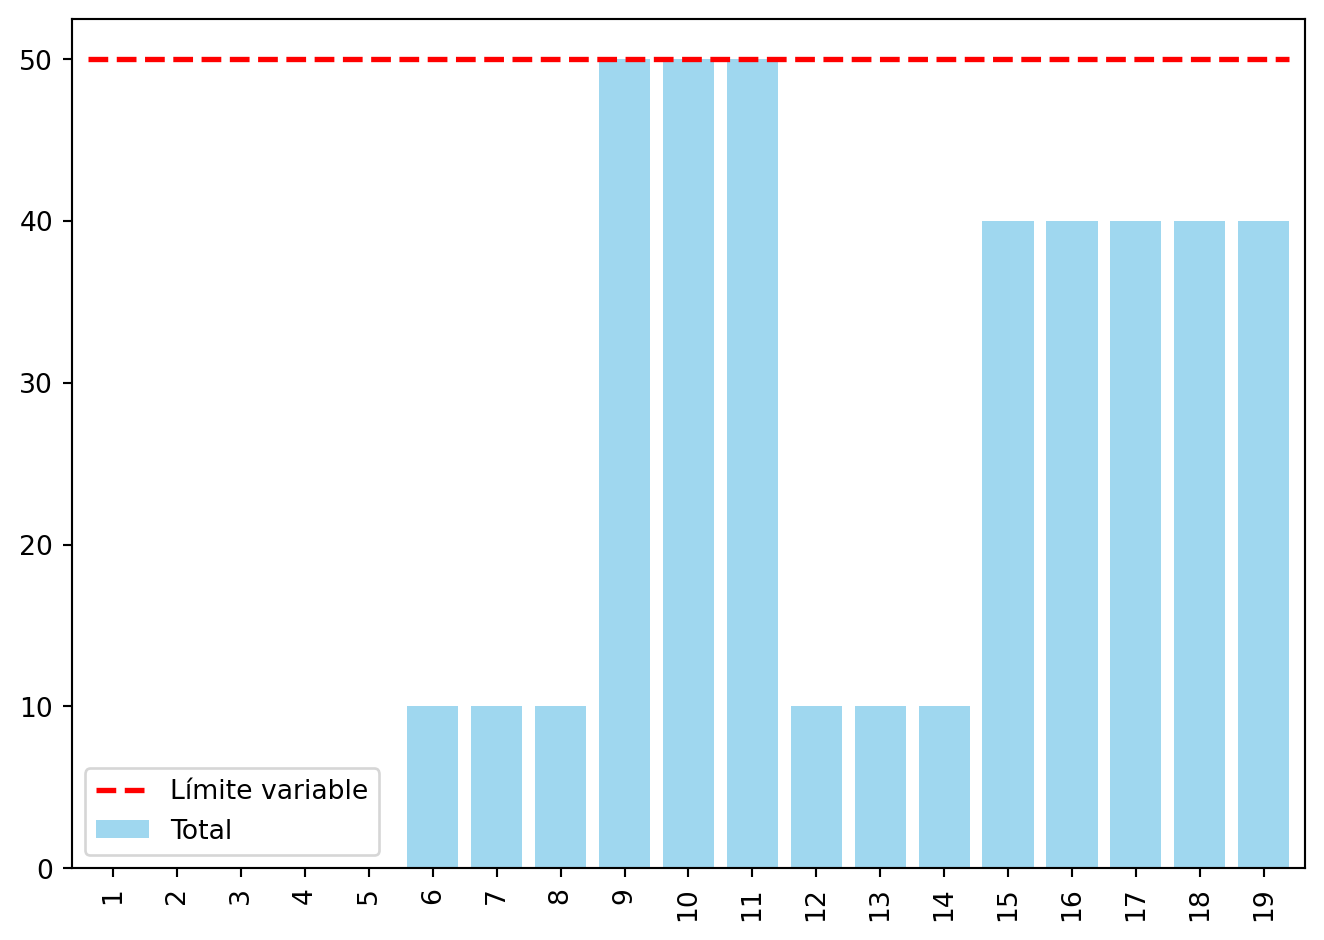

In [13]:
#| fig-cap: "Diagrama de cargas de agua tras la nivelación"
#| label: fig-cargasNivelado
plot_cargas(gantt_df=gantt_nivelado, limite_maximo_recursos=[cuota])

In [14]:
#| tbl-cap: "Exceso sobre la cuota, semana a semana, antes y después de nivelar (m³)"
#| label: tbl-exceso
exceso = (cargas - cuota).clip(lower=0); exceso_niv = (cargas_niveladas - cuota).clip(lower=0)
tabla = pd.DataFrame({'consumo inicial': cargas, 'exceso inicial': exceso, 'consumo nivelado': cargas_niveladas, 'exceso nivelado': exceso_niv})
tabla.loc['Total'] = tabla.sum()
display(tabla.astype(int).T)
Markdown(f'''Pico de **{int(cargas.max())} m³** con inicios más tempranos y **{int(cargas_niveladas.max())} m³** tras nivelar, frente a la cuota de {cuota}; el exceso pasa de {int(exceso.sum())} a **{int(exceso_niv.sum())} m³** con la misma duración ({duracion} semanas): ''' + ('el plan nivelado **cabe** en la cuota.' if exceso_niv.sum() == 0 else 'el plan nivelado **no cabe** del todo; quedan semanas por encima de la cuota.'))

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,Total
consumo inicial,0,0,0,0,0,20,20,10,50,90,90,50,40,40,0,0,0,0,0,410
exceso inicial,0,0,0,0,0,0,0,0,0,40,40,0,0,0,0,0,0,0,0,80
consumo nivelado,0,0,0,0,0,10,10,10,50,50,50,10,10,10,40,40,40,40,40,410
exceso nivelado,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Pico de **90 m³** con inicios más tempranos y **50 m³** tras nivelar, frente a la cuota de 50; el exceso pasa de 80 a **0 m³** con la misma duración (19 semanas): el plan nivelado **cabe** en la cuota.

## Apartado 2

In [15]:
display(Markdown(pregunta_2))

2. (A) Calcule el coste de las opciones legales: traer en cuba el exceso del plan inicial, traer en cuba el exceso del plan nivelado, y programar con asignación limitada a 50 m³ por semana (duración, retraso y penalidad). Calcule también el coste esperado de la propuesta del hidrante. ¿Cuál es la opción legal más barata?  

In [16]:
proyecto_limitado = proyecto.copy()
datos_asignados, gantt_asignado, dibujo_asig = proyecto_limitado.asignar(data=datos_proyecto.copy(), duration_label='duration',
                                                                      resource_label='agua_m3', maximo=[cuota], report=False, params=GANTT_PARAMS)
duracion_limitada = len(gantt_asignado.data.columns.drop('H_total'))
retraso = duracion_limitada - duracion
opciones = pd.DataFrame({'plan inicial + cuba': [float(exceso.sum()) * coste_cuba / 1000, 0, 0.0],
                         'nivelado + cuba': [float(exceso_niv.sum()) * coste_cuba / 1000, 0, 0.0],
                         f'asignación con límite de {cuota} m³': [0.0, retraso, retraso * penalidad],
                         'hidrante (propuesta)': [0.0, p_deteccion * corte, p_deteccion * (multa + corte * penalidad)]},
                        index=['agua en cuba (k€)', 'retraso (semanas; esperado en el hidrante)', 'penalidad o sanción (k€)'])
opciones.loc['coste (k€)'] = opciones.loc['agua en cuba (k€)'] + opciones.loc['penalidad o sanción (k€)']
display(opciones.round(1))
legales = opciones.loc['coste (k€)'].drop('hidrante (propuesta)')
Markdown(f'''Con la asignación limitada a {cuota} m³ el proyecto dura **{duracion_limitada}** semanas ({retraso} de retraso, {retraso * penalidad} k€). La opción legal más barata es **{legales.idxmin()}** ({legales.min():.1f} k€). El hidrante «cuesta» {opciones.loc['coste (k€)', 'hidrante (propuesta)']:.1f} k€ esperados''' + (', más que la opción legal: mal negocio además de infracción.' if opciones.loc['coste (k€)', 'hidrante (propuesta)'] > legales.min() else ', menos que la legal: la respuesta B no depende de esta cuenta.'))

,plan inicial + cuba,nivelado + cuba,asignación con límite de 50 m³,hidrante (propuesta)
agua en cuba (k€),1.1,0.0,0.0,0.0
retraso (semanas; esperado en el hidrante),0.0,0.0,0.0,1.0
penalidad o sanción (k€),0.0,0.0,0.0,21.0
coste (k€),1.1,0.0,0.0,21.0


Con la asignación limitada a 50 m³ el proyecto dura **19** semanas (0 de retraso, 0 k€). La opción legal más barata es **nivelado + cuba** (0.0 k€). El hidrante «cuesta» 21.0 k€ esperados, más que la opción legal: mal negocio además de infracción.

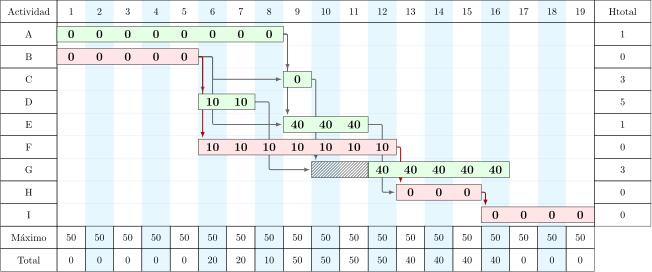

In [17]:
#| fig-cap: "Gantt con asignación limitada a la cuota"
#| label: fig-ganttAsignado
pinta_tikz(dibujo_asig)

## Apartado 3

In [18]:
display(Markdown(pregunta_3))

3. (B) Según el criterio y la norma de referencia, ¿es la cuota un límite del plan o un riesgo que se acepta? ¿Cabe el plan en la cuota tras nivelar, sin retraso? ¿Es el hidrante una opción de la tabla? ¿En qué escalón de la pirámide queda cada opción?  

**Norma y S16.** La cuota del bando es una limitación de uso del agua en situación excepcional (TRLA, arts. 55.2 y 58) y una condición del suministro de obra: es un **límite del plan**, con fecha y cifra, no un riesgo que se acepta pagando la penalidad. Si el plan cabe lo dice el diagrama de cargas: con inicios más tempranos el pico es de 90 m³ y el exceso de 80 m³; tras nivelar, 50 m³ y **cabe** en la cuota sin retraso. El hidrante **no es una opción de la tabla**: una toma no autorizada es infracción (TRLA, art. 116.3.b) y c); reglamento del servicio), y «si alguien pregunta es agua de la cuba» es una afirmación falsa (lección 19, C1). La opción correcta es la legal de menor coste: **nivelar**: el plan nivelado cabe en la cuota sin cuba ni retraso (0 k€). **S11.** La sequía sí es, además, un riesgo del proyecto: que el bando baje la cuota o cierre el punto de carga de las cubas tiene probabilidad e impacto, y entra en el registro. **S1.** El hidrante traslada el impacto a los demás usuarios de la red (ni siquiera compensa); la cuba **compensa** (el consumo es el mismo, pagado y traído de otra fuente); nivelar y asignar **minimizan** el pico sin cambiar el volumen; reducir el consumo (curado con láminas o filmógenos, reutilizar el agua de lavado) **evita** parte del impacto.

In [19]:
preguntas_test = [
    ('Una cuota semanal de agua fijada por el bando municipal de sequía es, para el cronograma de la obra…', ['un límite del plan, como el número de operarios: se nivela y, si no cabe, se asigna con límite o se compra el recurso fuera', 'un riesgo que se acepta si la penalidad por retraso es mayor que la sanción', 'una recomendación', 'una reserva de gestión'],
     'S16: la cuota tiene cifra y fecha; cabe o no cabe, y lo dice el diagrama de cargas.'),
    ('Tomar agua de un hidrante sin autorización durante las restricciones de sequía es…', ['una infracción (toma no autorizada; TRLA art. 116.3 y reglamento del servicio), no una opción del plan', 'una opción si se paga después el agua consumida', 'legal si el contador de obra no lo registra', 'legal de noche'],
     'S16: obtener el recurso saltándose la limitación es infracción.'),
    ('Nivelar las cargas de agua dentro de las holguras…', ['reduce el pico semanal sin cambiar el volumen total ni la duración', 'reduce el consumo total de agua', 'alarga el proyecto', 'elimina siempre el exceso sobre la cuota'],
     'Lección 11: la nivelación mueve actividades no críticas; el volumen es el mismo.'),
    ('Traer en camión cuba el agua que la cuota no permite es, en la pirámide de la sostenibilidad…', ['compensar: el mismo consumo, pagado y traído de otra fuente', 'evitar', 'minimizar', 'restaurar'],
     'S1: el impacto no se reduce; se paga y se traslada de fuente.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Sostenibilidad 20 — cuota de agua')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_sostenibilidad.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Sostenibilidad 20 — cuota de agua

::Sostenibilidad 20 — cuota de agua P1::Una cuota semanal de agua fijada por el bando municipal de sequía es, para el cronograma de la obra… {=un límite del plan, como el número de operarios: se nivela y, si no cabe, se asigna con límite o se compra el recurso fuera ~un riesgo que se acepta si la penalidad por retraso es mayor que la sanción ~una recomendación ~una reserva de gestión ####S16: la cuota tiene cifra y fecha; cabe o no cabe, y lo dice el diagrama de cargas.}

::Sostenibilidad 20 — cuota de agua P2::Tomar agua de un hidrante sin autorización durante las restricciones de sequía es… {~legal de noche =una infracción (toma no autorizada; TRLA art. 116.3 y reglamento del servicio), no una opción del plan ~legal si el contador de obra no lo registra ~una opción si se paga después el agua consumida ####S16: obtener el recurso saltándose la limitación es infracción.}

::Sostenibilidad 20 — cuota de agua P3::Nivelar las cargas de agua de

## Apartado 4

In [20]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al jefe de obra y qué comunica al cliente y al ayuntamiento? Aplique la rúbrica.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados, incluidos los que no están en la mesa (la comunidad, los trabajadores de la cadena, quien opere o desmantele lo construido, las generaciones siguientes) y qué pierde o gana cada uno con las cifras del bloque A; (2) formular al menos dos alternativas además de la propuesta, situándolas en la pirámide (compensar, restaurar, minimizar, evitar); (3) someter cada alternativa a tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería ante el inspector, el cliente o la prensa?) y ciclo de vida (¿quién paga el impacto y cuándo?)—; (4) decidir y redactar la comunicación con las cifras. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al jefe de obra: la tabla del apartado 2 y el plan nivelado con el calendario de riegos y curados semana a semana; las medidas de reducción (curado con láminas, agua de lavado recirculada) para bajar el consumo, no sólo el pico; y la cuba o la asignación limitada para lo que no quepa, con su coste (0.0 k€ en la opción elegida). Al cliente: la cuota del bando, el plan elegido y su efecto en la entrega. Al ayuntamiento, si hace falta: la solicitud motivada de una cuota mayor para las semanas de hormigonado, con el diagrama de cargas como justificación. Prueba de publicidad: ¿explicaría al concejal, en plena sequía, la manguera del hidrante «porque el contador no lo ve»?